# Munich rents: distributional modelling

A conditional rent distribution supplies a median and prediction intervals
for apartments with specified characteristics. This study fits Gaussian
location-scale models to log monthly rent and compares a constant residual
scale with a scale that varies with floor area and construction year. It
evaluates the complete choice of specification and stopping point by holding
out districts, then saves and reloads one fitted model.

The response is a historical rent, not a recommended price or an estimate of
the effect of renovating an apartment. The companion studies describe
[](munich_rents.ipynb) and [](working_a_model.ipynb).

This case teaches a complete distributional prediction procedure: nested grouped
validation chooses the scale specification and stopping point, then the selected model
returns rent intervals and a reusable artifact.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | a predictive rent distribution for apartments in districts excluded from fitting |
| **Observed response** | monthly net rent in the 1999 Munich survey |
| **Estimand** | conditional quantiles of historical rent given apartment characteristics, evaluated on unseen districts |
| **Units** | euros per month; log rent means the natural log of rent divided by one euro |
| **Sampling unit** | one apartment |
| **Dependence** | apartments share districts; adjacent districts may remain dependent |
| **Split / resampling unit** | whole districts in five outer folds and three inner folds |
| **Tuning** | inner-fold joint negative log likelihood selects one of two scale specifications and a diagonal stopping point |
| **Uncertainty** | a district bootstrap of fixed outer predictions describes evaluation variability, conditional on the fitted procedures |
| **Claim type** | predictive performance for the stated historical population and split design |
:::


## Data and predictors

`munich_rent()` supplies the 3,082 apartments distributed as `rent99` in
`gamlss.data`. The [upstream data reference](https://search.r-project.org/CRAN/refmans/gamlss.data/html/rent99.html)
specifies euros for rent, square metres for floor area, and `cheating` as the
central-heating indicator. The dataset loader and the upstream reference both report euros; no currency conversion
is applied here.

`rentsqm` is rent divided by area and therefore contains the response; it is
excluded. Location quality is represented by two indicators relative to
average quality. Construction year, amenities and location quality are
assumed available when a prediction is requested. District codes define the
validation groups, and do not enter as numerical predictors.

In [1]:
import json
import tempfile
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
from IPython.display import Markdown, display

import mboostrs as mb
from mboostrs import plot as mbplot

# SVG charts can be embedded in both the HTML and PDF editions of the book.
alt.renderers.enable("svg")

RendererRegistry.enable('svg')

In [2]:
raw = mb.datasets.munich_rent(output="polars")

# Exclude rentsqm: it is calculated from the response and would leak rent.
data = raw.select(
    "rent", "area", "yearc", "location", "bath", "kitchen", "cheating", "district",
)

# Fix these encodings before splitting; none estimates a value from outcomes.
data = data.with_columns(
    (pl.col("location") == 2).cast(pl.Int64).alias("good"),
    (pl.col("location") == 3).cast(pl.Int64).alias("top"),
)
assert data.null_count().sum_horizontal().item() == 0
assert (data["rent"] > 0).all()
display(data.select("rent", "area", "yearc").describe())

statistic,rent,area,yearc
str,f64,f64,f64
"""count""",3082.0,3082.0,3082.0
"""null_count""",0.0,0.0,0.0
"""mean""",459.437179,67.374757,1956.306295
"""std""",195.656638,23.720446,22.308868
"""min""",40.512821,20.0,1918.0
"""25%""",322.0,51.0,1939.0
"""50%""",427.025635,65.0,1959.0
"""75%""",559.435913,81.0,1972.0
"""max""",1843.384644,160.0,1997.0


## Location and scale specifications

Let $Y$ denote monthly rent and $L=\log(Y/1\,\mathrm{euro})$.
The fitted model assumes $L\mid x\sim N(\mu(x),\sigma(x)^2)$.
The location predictor has smooth terms for area and construction year,
plus linear effects for the indicators. The alternative scale predictor
uses smooth terms for area and year; the baseline estimates a constant scale.
Every selected term is an association conditional on this specification.

The median rent is $\exp(\mu)$ euros, while its conditional mean is
$\exp(\mu+\sigma^2/2)$ euros. A central interval is obtained by exponentiating
the corresponding Gaussian quantiles. Thus `mu` on this fit is a mean log
rent, and exponentiating it does not produce a mean rent.

Both scale specifications include the term `1`: the estimated constant
that lets boosting move the average log scale off its starting value. In a
formula it names the intercept, as it does in R's `log_rent ~ 1`; one
coefficient is fitted on an implicit column of ones, and no constant column
is added to the data.

In [3]:
# The response transform is declared in the formula: the fit works on
# log(rent), and the model remembers the step, so intervals, PIT values and
# euro-scale scores below all come back on the original scale.
mu_formula = (
    "log(rent) ~ bbs(area, df=4) + bbs(yearc, df=4) + "
    "bols(good) + bols(top) + bols(bath) + bols(kitchen) + bols(cheating)"
)
specifications = {
    "constant scale": {
        "mu": mu_formula,
        "sigma": "log(rent) ~ 1",
    },
    "varying scale": {
        "mu": mu_formula,
        "sigma": "log(rent) ~ 1 + bbs(area, df=4) + bbs(yearc, df=4)",
    },
}

# The diagonal grid advances location and scale by the same cycle count.
grid = [[m, m] for m in (20, 40, 80, 160, 320, 640)]
display(Markdown("```json\n" + json.dumps(specifications, indent=2) + "\n```"))

```json
{
  "constant scale": {
    "mu": "log(rent) ~ bbs(area, df=4) + bbs(yearc, df=4) + bols(good) + bols(top) + bols(bath) + bols(kitchen) + bols(cheating)",
    "sigma": "log(rent) ~ 1"
  },
  "varying scale": {
    "mu": "log(rent) ~ bbs(area, df=4) + bbs(yearc, df=4) + bols(good) + bols(top) + bols(bath) + bols(kitchen) + bols(cheating)",
    "sigma": "log(rent) ~ 1 + bbs(area, df=4) + bbs(yearc, df=4)"
  }
}
```

## Validation by district

Each outer fold holds out whole districts. Inside its training portion,
three grouped folds select the stopping point for each scale specification.
The specification with the smaller inner risk supplies the selected procedure's
outer predictions. All six diagonal grid points are read from one boosting
path per inner fold; this search does not optimize separate stopping budgets
over the full location-scale grid. L2 stabilization rescales each parameter's
gradient and is held fixed throughout the procedure.

The comparison assumes a future district can be described by the observed
apartment characteristics. It does not estimate a new district's random
effect or integrate a fitted distribution over unknown group effects.
Geographic blocking would be needed for a task requiring greater separation
between training and prediction locations.

In [4]:
def tuned_fit(frame, specification, folds):
    """Fit and select stopping using only this outer fold's training rows."""
    fitted = mb.gamboostLSS(
        specification,
        frame,
        family=mb.GaussianLSS(),
        control=mb.boost_control(640, 0.1),
        stabilization="L2",
    )
    cv = fitted.cvrisk(folds=folds, grid=grid)

    # LSS truncation refits at the chosen budgets; it is not a cheap slice.
    selected = fitted.with_mstop(cv.optimal_mstop)
    return selected, cv


In [5]:
def score_rents(fit, held_out):
    """Evaluate the lognormal rent distribution on untouched apartments."""
    # The fit carries the response transform, so the evaluation scores
    # rent directly: the density already includes the change-of-variables
    # factor, and the interval bounds come back in euros.
    evaluation = mb.evaluate_distribution(
        fit, held_out, "rent", data_role="external", levels=(0.9,),
    )
    mu = evaluation.parameters["mu"]
    sigma = evaluation.parameters["sigma"]

    # Convert Gaussian log-rent quantiles to rent quantiles, in euros.
    lower = np.exp(mu - 1.6448536269514722 * sigma)
    upper = np.exp(mu + 1.6448536269514722 * sigma)
    rent = held_out["rent"].to_numpy()

    rent_log_score = evaluation.negative_log_score
    return held_out.select("district", "area", "rent").with_columns(
        pl.Series("log score", rent_log_score),
        pl.Series("covered", ((lower <= rent) & (rent <= upper)).astype(float)),
        pl.Series("width", upper - lower),
        pl.Series("pit", evaluation.pit),
    )


The outer loop keeps each district entirely in training or testing. Its inner
comparison chooses the specification before `score_rents` receives the outer
test frame. Both candidates are retained for comparison, while the
`inner-selected` rows below evaluate the procedure's actual choice.

In [6]:
outer = mb.grouped_folds(data["district"].to_numpy(), B=5, seed=2026)

fold_rows = []

evaluation_frames = []

representative = None


In [7]:
for fold in range(5):
    # Define the external test districts for this fold.
    is_test = np.asarray(outer)[:, fold] == 0
    train = data.filter(pl.Series(~is_test))
    test = data.filter(pl.Series(is_test))
    assert set(train["district"]).isdisjoint(set(test["district"]))

    inner = mb.grouped_folds(train["district"].to_numpy(), B=3, seed=410 + fold)
    candidates = {}

    # Tune both candidates on the same training-only folds.
    for name, specification in specifications.items():
        fit, cv = tuned_fit(train, specification, inner)
        candidates[name] = (fit, cv)
        fold_rows.append({
            "fold": fold + 1,
            "model": name,
            "mstop": cv.optimal_mstop[0],
            "inner log score": float(np.min(cv.aggregate)),
            "upper boundary": cv.at_boundary(),
        })

    chosen = min(candidates, key=lambda name: float(np.min(candidates[name][1].aggregate)))

    # Only now inspect the outer outcomes and record both candidates' scores.
    for name, (fit, cv) in candidates.items():
        evaluated = score_rents(fit, test).with_columns(
            pl.lit(fold + 1).alias("fold"),
            pl.lit(name).alias("model"),
            pl.lit(name == chosen).alias("selected"),
        )
        evaluation_frames.append(evaluated)

    if fold == 0:
        representative = (candidates[chosen][0], train, test, chosen)


/tmp/ipykernel_67491/3669887043.py:6: ExtrapolationWarning: 1 value(s) of 'rent' lie below its smallest training value 54.9231; log(rent) holds them there, so their effect is the one at the training minimum
  evaluation = mb.evaluate_distribution(


In [8]:
fold_table = pl.DataFrame(fold_rows)

evaluations = pl.concat(evaluation_frames)

selected_rows = evaluations.filter(pl.col("selected")).with_columns(
    pl.lit("inner-selected").alias("model"),
)

all_scores = pl.concat([evaluations, selected_rows])

display(fold_table)


fold,model,mstop,inner log score,upper boundary
i64,str,i64,f64,bool
1,"""constant scale""",40,0.269434,false
1,"""varying scale""",40,0.237675,false
2,"""constant scale""",80,0.236045,false
2,"""varying scale""",320,0.205094,false
3,"""constant scale""",40,0.243853,false
3,"""varying scale""",40,0.217402,false
4,"""constant scale""",40,0.237782,false
4,"""varying scale""",40,0.21122,false
5,"""constant scale""",80,0.226049,false


The score table below uses negative log density on the original euro scale.
If $p_L$ is the fitted log-rent density, then
$p_Y(y)=p_L(\log y)/y$, so $-\log p_Y(y)=-\log p_L(\log y)+\log y$.
The evaluation carries this change-of-variables factor itself, because the
model was fitted with the transform declared. Lower log scores are better.
Coverage measures the share of observed rents in the central 90% interval;
width measures that interval in euros per month. These intervals depend on
the fitted distribution and do not have a conformal coverage guarantee.

In [9]:
# Average per apartment: the intended population weights apartments equally.
summary = all_scores.group_by("model").agg(
    pl.col("log score").mean(),
    pl.col("covered").mean().alias("90% coverage"),
    pl.col("width").mean().alias("mean width, euros"),
).sort("model")
display(summary)

constant_score = summary.filter(pl.col("model") == "constant scale")["log score"].item()
varying_score = summary.filter(pl.col("model") == "varying scale")["log score"].item()
comparison_sentence = (
    f"The varying-scale model changes mean outer log score by {varying_score - constant_score:+.4f} "
    "relative to constant scale; negative values favor varying scale."
)
selected_coverage = summary.filter(pl.col("model") == "inner-selected")["90% coverage"].item()
boundary_count = int(fold_table["upper boundary"].sum())

model,log score,90% coverage,"mean width, euros"
str,f64,f64,f64
"""constant scale""",6.278271,0.911421,462.154679
"""inner-selected""",6.24934,0.918235,454.361745
"""varying scale""",6.24934,0.918235,454.361745


{eval}`comparison_sentence` The procedure selected inside each outer training
sample covers {eval}`f"{selected_coverage:.1%}"` of the held-out rents with its
nominal 90% intervals. The search reaches the largest stopping point in
{eval}`boundary_count` of its ten specification-specific fits; a boundary
result describes this finite search budget rather than an interior optimum.

## Evaluation uncertainty and calibration

The next calculation resamples districts, retaining all apartments within
each sampled district. Its percentile interval describes variation in mean
log score for the selected procedure, conditional on the recorded predictions.
It does not repeat fitting or account fully for the overlap between training
folds. Coverage by floor-area band and the probability integral transform
(PIT), the fitted CDF evaluated at each outcome, check aspects of calibration
that aggregate coverage can hide.

In [10]:
# Resample districts as blocks, preserving the number of apartments in each.
group_scores = selected_rows.group_by("district").agg(
    pl.col("log score").sum().alias("total"),
    pl.len().alias("n"),
)
rng = np.random.default_rng(88)
draws = rng.integers(0, group_scores.height, size=(500, group_scores.height))
sampled_totals = group_scores["total"].to_numpy()[draws].sum(axis=1)
sampled_counts = group_scores["n"].to_numpy()[draws].sum(axis=1)
bootstrap = sampled_totals / sampled_counts
score_interval = np.quantile(bootstrap, [0.025, 0.975])

display(pl.DataFrame({
    "mean log score": [selected_rows["log score"].mean()],
    "bootstrap lower": [score_interval[0]],
    "bootstrap upper": [score_interval[1]],
}))

mean log score,bootstrap lower,bootstrap upper
f64,f64,f64
6.24934,6.211677,6.290405


"area, square metres",apartments,90% coverage,"mean width, euros"
str,u32,f64,f64
"""50–89""",1908,0.913522,443.590378
"""90 and above""",489,0.93047,716.03095
"""under 50""",685,0.922628,297.566895


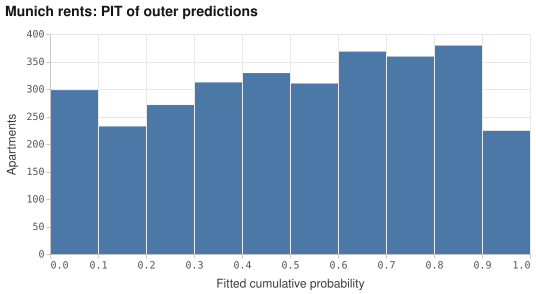

In [11]:
# Prespecified area bands expose coverage differences hidden by one average.
by_area = selected_rows.with_columns(
    pl.when(pl.col("area") < 50).then(pl.lit("under 50"))
    .when(pl.col("area") < 90).then(pl.lit("50–89"))
    .otherwise(pl.lit("90 and above")).alias("area, square metres")
).group_by("area, square metres").agg(
    pl.len().alias("apartments"),
    pl.col("covered").mean().alias("90% coverage"),
    pl.col("width").mean().alias("mean width, euros"),
).sort("area, square metres")
display(by_area)

pit_chart = alt.Chart(selected_rows).mark_bar().encode(
    x=alt.X("pit:Q", bin=alt.Bin(step=0.1), title="Fitted cumulative probability"),
    y=alt.Y("count():Q", title="Apartments"),
).properties(title="Munich rents: PIT of outer predictions", width=480, height=220)
display(pit_chart)

## Selected effects and prediction profiles

For illustration, the following tables and profile use the model selected
inside the first outer training sample. Update counts show which learners
the algorithm used for each parameter; they are not probabilities that an
association is real. The profile changes floor area while holding the other
characteristics at training-sample reference values. Its interval describes
individual rents under that profile, not confidence in the estimated curve.

In [12]:
# Inspect the first outer fit; it was not chosen by its test performance.
fit, train, test, chosen = representative
path = fit.path_frame(output="polars")
update_counts = path.group_by("parameter", "learner").len(name="updates")
display(update_counts.sort("parameter", "updates", descending=[False, True]))

# Hold other characteristics at training reference values while varying area.
area_values = np.linspace(
    float(train["area"].quantile(.05)), float(train["area"].quantile(.95)), 80,
)
reference_columns = {}
for name in ("yearc", "good", "top", "bath", "kitchen", "cheating"):
    reference_columns[name] = np.repeat(float(train[name].median()), len(area_values))

profile = pl.DataFrame(reference_columns).with_columns(pl.Series("area", area_values))
parameters = fit.predict(newdata=profile, type="response")
profile = profile.with_columns(
    pl.Series("median", np.exp(parameters["mu"])),
    pl.Series("lower", np.exp(parameters["mu"] - 1.6448536269514722 * parameters["sigma"])),
    pl.Series("upper", np.exp(parameters["mu"] + 1.6448536269514722 * parameters["sigma"])),
)

parameter,learner,updates
str,str,u32
"""mu""","""area""",12
"""mu""","""yearc""",8
"""mu""","""cheating""",8
"""mu""","""good""",5
"""mu""","""top""",3
"""mu""","""bath""",2
"""mu""","""kitchen""",2
"""sigma""","""yearc""",31
"""sigma""","""area""",9


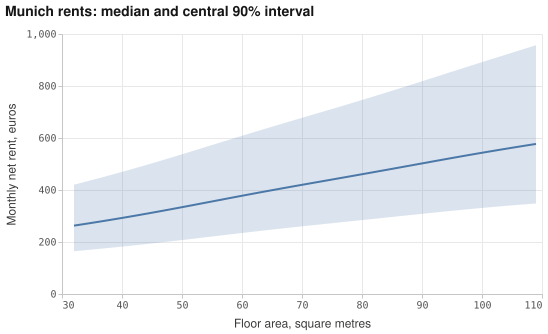

In [13]:
# The band describes individual rents, not uncertainty about the median curve.
base = alt.Chart(profile).encode(x=alt.X("area:Q", title="Floor area, square metres"))
band = base.mark_area(opacity=.2).encode(
    y=alt.Y("lower:Q", title="Monthly net rent, euros"), y2="upper:Q",
)
line = base.mark_line().encode(y="median:Q")
display((band + line).properties(
    title="Munich rents: median and central 90% interval", width=480, height=260,
))

profile_sentence = (
    f"Across the displayed area range, the predicted median changes from {profile['median'][0]:.0f} "
    f"to {profile['median'][-1]:.0f} euros per month under the {chosen} specification."
)

{eval}`profile_sentence` Larger apartments would ordinarily be expected to
have higher total rents, but this profile also holds construction year and
amenities fixed and does not establish an effect of increasing floor area.
Differences associated with construction year can represent building quality,
renovation and regulation as well as age. Amenity indicators may also proxy
unrecorded quality. The fitted scale combines unexplained apartment variation
with location information omitted from the specification.

## Extension: saving and scoring

`save_model` writes a versioned JSON artifact, and `load_model` reconstructs
its Python predictor. The check below compares every location and scale
prediction before and after loading. The artifact saved here is the full
training checkpoint: it retains the training frame and the state a refit
needs. `save_model(..., scoring_only=True)` keeps what prediction reads and
drops the rest — the response column leaves the retained frame, and the
loaded model refuses `update`/`with_mstop` with the retention error. The R
reader (`mboostrs/R/mboostrs_load.R`) loads distributional artifacts for
inspection — parameter names, per-parameter step counts and offsets — and
scores linear `glmboost` artifacts directly; predicting from an LSS
artifact needs the Python reader, which owns the spline machinery.

In [14]:
# Archive this fitted model, then verify predictions through the public reader.
before = fit.predict(newdata=test, type="response")
with tempfile.TemporaryDirectory() as directory:
    artifact = mb.save_model(fit, Path(directory) / "munich-log-rent.json")
    artifact_bytes = artifact.stat().st_size
    restored = mb.load_model(artifact)

after = restored.predict(newdata=test, type="response")
differences = []
for parameter in before:
    np.testing.assert_allclose(before[parameter], after[parameter], rtol=1e-12, atol=1e-12)
    differences.append(float(np.max(np.abs(before[parameter] - after[parameter]))))

max_difference = max(differences)
display(pl.DataFrame({
    "artifact bytes": [artifact_bytes],
    "maximum prediction difference": [max_difference],
}))

artifact bytes,maximum prediction difference
i64,f64
529274,0.0


## Conclusions and limitations

The analysis produces an evaluated procedure for choosing a scale
specification, interpretable parameter predictors, and a Python artifact
whose predictions survive a save/load round trip. Its performance is reported
above even when varying scale does not improve the score. The five folds
partition one historical survey; they do not establish performance on another
city, another survey year, or today's rents. The analyst has also restricted
the family to a lognormal rent distribution and searched only a diagonal
stopping grid. Heavy tails, further geographic structure and independent
calibration data could change the assessment.

See [](distributional_comparison.ipynb) for comparisons with other libraries,
[](specification_search_validation.ipynb) for repeated evaluation of search,
and [](../usage/gamboostlss.ipynb) for the API.